# 06 · Statistical Analysis and Uncertainty Quantification

**Objective.** Summarize per-sample TCERS values with uncertainty, compare methods with paired tests, quantify effect sizes, and correct for multiple comparisons.

## Analysis plan

1. **Descriptive statistics** per method: count, mean, standard deviation, median, interquartile range, and bootstrap 95% confidence intervals.
2. **Distribution diagnostics** with Shapiro–Wilk. With small samples, normality tests have low power, so the Wilcoxon signed-rank test is the primary paired test and the paired t-test is secondary.
3. **Paired comparisons** on samples evaluated by both methods: Wilcoxon signed-rank, paired t-test, and Cohen's $d_z$ effect size.
4. **Multiplicity control** with Holm–Bonferroni across all pairwise comparisons.
5. **Prediction consistency** summarized and compared separately from TCERS.
6. **Visual diagnostics**: paired distributions, confidence intervals, and pairwise difference distributions.

> **Inference safeguard.** Do not report significance from an uncorrected p-value. Report effect sizes and confidence intervals alongside p-values, and describe the sample and perturbation protocol.

## Artifacts

- `experiments/results/statistical_descriptives.csv`
- `experiments/results/statistical_normality.csv`
- `experiments/results/statistical_pairwise_tests.csv`
- `experiments/results/prediction_consistency_summary.csv`
- `experiments/results/prediction_consistency_pairwise.csv`
- `figures/statistical_distributions.png`
- `figures/statistical_confidence_intervals.png`
- `figures/statistical_paired_differences.png`
- `figures/statistical_difference_heatmap.png`

## Environment and input table

The analysis consumes `tcers_per_sample.csv` from Notebook 05. Paired tests require that each sample appears for every compared method; the code below aligns on sample index and reports the number of complete pairs.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image as DisplayImage, display
from scipy.stats import shapiro, ttest_rel, wilcoxon

from src.config import ExperimentConfig
from src.utils import seed_everything

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})

config = ExperimentConfig()
config.create_directories()
seed_everything(config.seed)

tc_path = config.output_root / "tcers_per_sample.csv"
if not tc_path.exists():
    raise FileNotFoundError("tcers_per_sample.csv not found. Run notebook 05 first.")

tcers_table = pd.read_csv(tc_path)
methods = sorted(tcers_table["method"].unique())
print(f"Loaded {len(tcers_table)} rows from {tc_path}")
print(f"Methods: {methods}")
print(f"Samples per method:\n{tcers_table.groupby('method')['sample'].nunique()}")

Loaded 24 rows from experiments\results\tcers_per_sample.csv
Methods: ['Grad-CAM', 'Integrated Gradients', 'Occlusion']
Samples per method:
method
Grad-CAM                8
Integrated Gradients    8
Occlusion               8
Name: sample, dtype: int64


## Bootstrap confidence intervals

Bootstrap intervals are used for the descriptive table because TCERS is bounded and likely non-normal. The seed is fixed so the intervals are reproducible. The number of resamples is recorded implicitly by the code; increase it for a final analysis if needed.

In [2]:
def bootstrap_ci(values, n_boot=2000, confidence=0.95, seed=config.seed):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    if len(values) < 2:
        return float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    means = np.array([
        rng.choice(values, size=len(values), replace=True).mean()
        for _ in range(n_boot)
    ])
    alpha = (1 - confidence) / 2
    return float(np.quantile(means, alpha)), float(np.quantile(means, 1 - alpha))

descriptive_rows = []
for method, frame in tcers_table.groupby("method"):
    values = frame["tcers"].dropna().to_numpy()
    lower, upper = bootstrap_ci(values)
    descriptive_rows.append({
        "method": method,
        "n": len(values),
        "mean": float(values.mean()) if len(values) else float("nan"),
        "std": float(values.std(ddof=1)) if len(values) > 1 else float("nan"),
        "median": float(np.median(values)) if len(values) else float("nan"),
        "q1": float(np.percentile(values, 25)) if len(values) else float("nan"),
        "q3": float(np.percentile(values, 75)) if len(values) else float("nan"),
        "min": float(values.min()) if len(values) else float("nan"),
        "max": float(values.max()) if len(values) else float("nan"),
        "ci95_lower": lower,
        "ci95_upper": upper,
    })

descriptive = pd.DataFrame(descriptive_rows).sort_values("mean", ascending=False)
descriptive.to_csv(config.output_root / "statistical_descriptives.csv", index=False)
descriptive

,method,n,mean,std,median,q1,q3,min,max,ci95_lower,ci95_upper
0,Grad-CAM,8,0.879851,0.081441,0.898481,0.836155,0.942542,0.756561,0.969570,0.824190,0.930269
2,Occlusion,8,0.771700,0.048592,0.750474,0.741888,0.799582,0.723393,0.853471,0.742124,0.805775
1,Integrated Gradients,8,0.671931,0.042770,0.672286,0.656556,0.704494,0.594426,0.726775,0.641965,0.698608


## Normality diagnostics

Shapiro–Wilk tests are reported for transparency, but they are not used to gate the primary analysis. With small samples, failure to reject normality is weak evidence, and rejecting normality is common for bounded scores.

In [3]:
normality_rows = []
for method, frame in tcers_table.groupby("method"):
    values = frame["tcers"].dropna().to_numpy()
    if len(values) >= 3:
        statistic, p_value = shapiro(values)
    else:
        statistic, p_value = float("nan"), float("nan")
    normality_rows.append({
        "method": method,
        "n": len(values),
        "shapiro_w": float(statistic),
        "p_value": float(p_value),
        "reject_normality_at_0.05": bool(p_value < 0.05) if np.isfinite(p_value) else False,
    })

normality = pd.DataFrame(normality_rows)
normality.to_csv(config.output_root / "statistical_normality.csv", index=False)
normality

,method,n,shapiro_w,p_value,reject_normality_at_0.05
0,Grad-CAM,8,0.883289,0.202409,False
1,Integrated Gradients,8,0.953849,0.749891,False
2,Occlusion,8,0.862928,0.128399,False


## Paired comparisons

For each pair of methods, samples are aligned on `sample`. The difference is defined as first minus second, so a positive mean difference means the first method has higher TCERS.

- **Wilcoxon signed-rank** is the primary test: it does not assume normality and is appropriate for bounded, paired scores.
- **Paired t-test** is reported as a secondary analysis for readers who require it.
- **Cohen's $d_z$** is the standardised mean paired difference: $d_z = \bar{d} / s_d$.
- **Holm–Bonferroni** controls the family-wise error rate across all method pairs.

In [4]:
pair_rows = []
for first, second in combinations(methods, 2):
    aligned = tcers_table.pivot_table(
        index="sample", columns="method", values="tcers"
    ).dropna(subset=[first, second])
    difference = aligned[first] - aligned[second]
    n_pairs = len(difference)

    if n_pairs >= 3 and not np.allclose(difference, 0):
        wilcoxon_statistic, wilcoxon_p = wilcoxon(
            aligned[first], aligned[second], zero_method="wilcox", alternative="two-sided"
        )
    else:
        wilcoxon_statistic, wilcoxon_p = float("nan"), float("nan")

    if n_pairs >= 3:
        t_statistic, t_p = ttest_rel(aligned[first], aligned[second])
    else:
        t_statistic, t_p = float("nan"), float("nan")

    standard_deviation = difference.std(ddof=1) if n_pairs > 1 else float("nan")
    cohens_dz = difference.mean() / standard_deviation if standard_deviation and standard_deviation > 0 else float("nan")

    pair_rows.append({
        "comparison": f"{first} vs {second}",
        "method_a": first,
        "method_b": second,
        "n_pairs": n_pairs,
        "mean_difference_a_minus_b": float(difference.mean()),
        "std_difference": float(standard_deviation),
        "wilcoxon_statistic": float(wilcoxon_statistic),
        "wilcoxon_p": float(wilcoxon_p),
        "paired_t_statistic": float(t_statistic),
        "paired_t_p": float(t_p),
        "cohens_dz": float(cohens_dz),
    })

comparisons = pd.DataFrame(pair_rows)
comparisons

,comparison,method_a,method_b,n_pairs,mean_difference_a_minus_b,std_difference,wilcoxon_statistic,wilcoxon_p,paired_t_statistic,paired_t_p,cohens_dz
0,Grad-CAM vs Integrated Gradients,Grad-CAM,Integrated Gradients,8,0.207920,0.110095,0.0,0.007812,5.341613,0.001074,1.888545
1,Grad-CAM vs Occlusion,Grad-CAM,Occlusion,8,0.108151,0.069706,0.0,0.007812,4.388383,0.003202,1.551528
2,Integrated Gradients vs Occlusion,Integrated Gradients,Occlusion,8,-0.099768,0.054025,0.0,0.007812,-5.223260,0.001221,-1.846701


In [5]:
def holm_correction(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running_max = 0.0
    for rank, index in enumerate(order):
        candidate = (len(p_values) - rank) * p_values[index]
        running_max = max(running_max, candidate)
        adjusted[index] = min(running_max, 1.0)
    return adjusted

comparisons["wilcoxon_p_holm"] = holm_correction(comparisons["wilcoxon_p"].fillna(1.0).to_numpy())
comparisons["paired_t_p_holm"] = holm_correction(comparisons["paired_t_p"].fillna(1.0).to_numpy())
comparisons.to_csv(config.output_root / "statistical_pairwise_tests.csv", index=False)
comparisons

,comparison,method_a,method_b,n_pairs,mean_difference_a_minus_b,std_difference,wilcoxon_statistic,wilcoxon_p,paired_t_statistic,paired_t_p,cohens_dz,wilcoxon_p_holm,paired_t_p_holm
0,Grad-CAM vs Integrated Gradients,Grad-CAM,Integrated Gradients,8,0.207920,0.110095,0.0,0.007812,5.341613,0.001074,1.888545,0.023438,0.003222
1,Grad-CAM vs Occlusion,Grad-CAM,Occlusion,8,0.108151,0.069706,0.0,0.007812,4.388383,0.003202,1.551528,0.023438,0.003222
2,Integrated Gradients vs Occlusion,Integrated Gradients,Occlusion,8,-0.099768,0.054025,0.0,0.007812,-5.223260,0.001221,-1.846701,0.023438,0.003222


## Prediction consistency

Prediction consistency is a separate outcome. It is summarized per method and compared with the same paired Wilcoxon procedure. A method can have high TCERS while the classifier itself is fragile, so the two families of results must be reported together.

In [6]:
consistency_summary = (
    tcers_table.groupby("method")["prediction_consistency"]
    .agg(observations="count", mean="mean", std="std", minimum="min", maximum="max")
    .reset_index()
)
consistency_summary.to_csv(config.output_root / "prediction_consistency_summary.csv", index=False)
consistency_summary

,method,observations,mean,std,minimum,maximum
0,Grad-CAM,8,0.919643,0.096872,0.785714,1.0
1,Integrated Gradients,8,0.919643,0.096872,0.785714,1.0
2,Occlusion,8,0.919643,0.096872,0.785714,1.0


In [7]:
consistency_rows = []
for first, second in combinations(methods, 2):
    aligned = tcers_table.pivot_table(
        index="sample", columns="method", values="prediction_consistency"
    ).dropna(subset=[first, second])
    difference = aligned[first] - aligned[second]
    if len(difference) >= 3 and not np.allclose(difference, 0):
        statistic, p_value = wilcoxon(aligned[first], aligned[second])
    else:
        statistic, p_value = float("nan"), float("nan")
    consistency_rows.append({
        "comparison": f"{first} vs {second}",
        "n_pairs": len(difference),
        "mean_difference": float(difference.mean()),
        "wilcoxon_statistic": float(statistic),
        "wilcoxon_p": float(p_value),
    })

consistency_comparisons = pd.DataFrame(consistency_rows)
consistency_comparisons["wilcoxon_p_holm"] = holm_correction(
    consistency_comparisons["wilcoxon_p"].fillna(1.0).to_numpy()
)
consistency_comparisons.to_csv(config.output_root / "prediction_consistency_pairwise.csv", index=False)
consistency_comparisons

,comparison,n_pairs,mean_difference,wilcoxon_statistic,wilcoxon_p,wilcoxon_p_holm
0,Grad-CAM vs Integrated Gradients,8,0.0,NaN,NaN,1.0
1,Grad-CAM vs Occlusion,8,0.0,NaN,NaN,1.0
2,Integrated Gradients vs Occlusion,8,0.0,NaN,NaN,1.0


## Visual diagnostics

The first plot shows the per-sample distributions. The second shows bootstrap confidence intervals for the means. The third shows paired differences, which is the quantity actually tested. The fourth summarizes all pairwise mean differences.

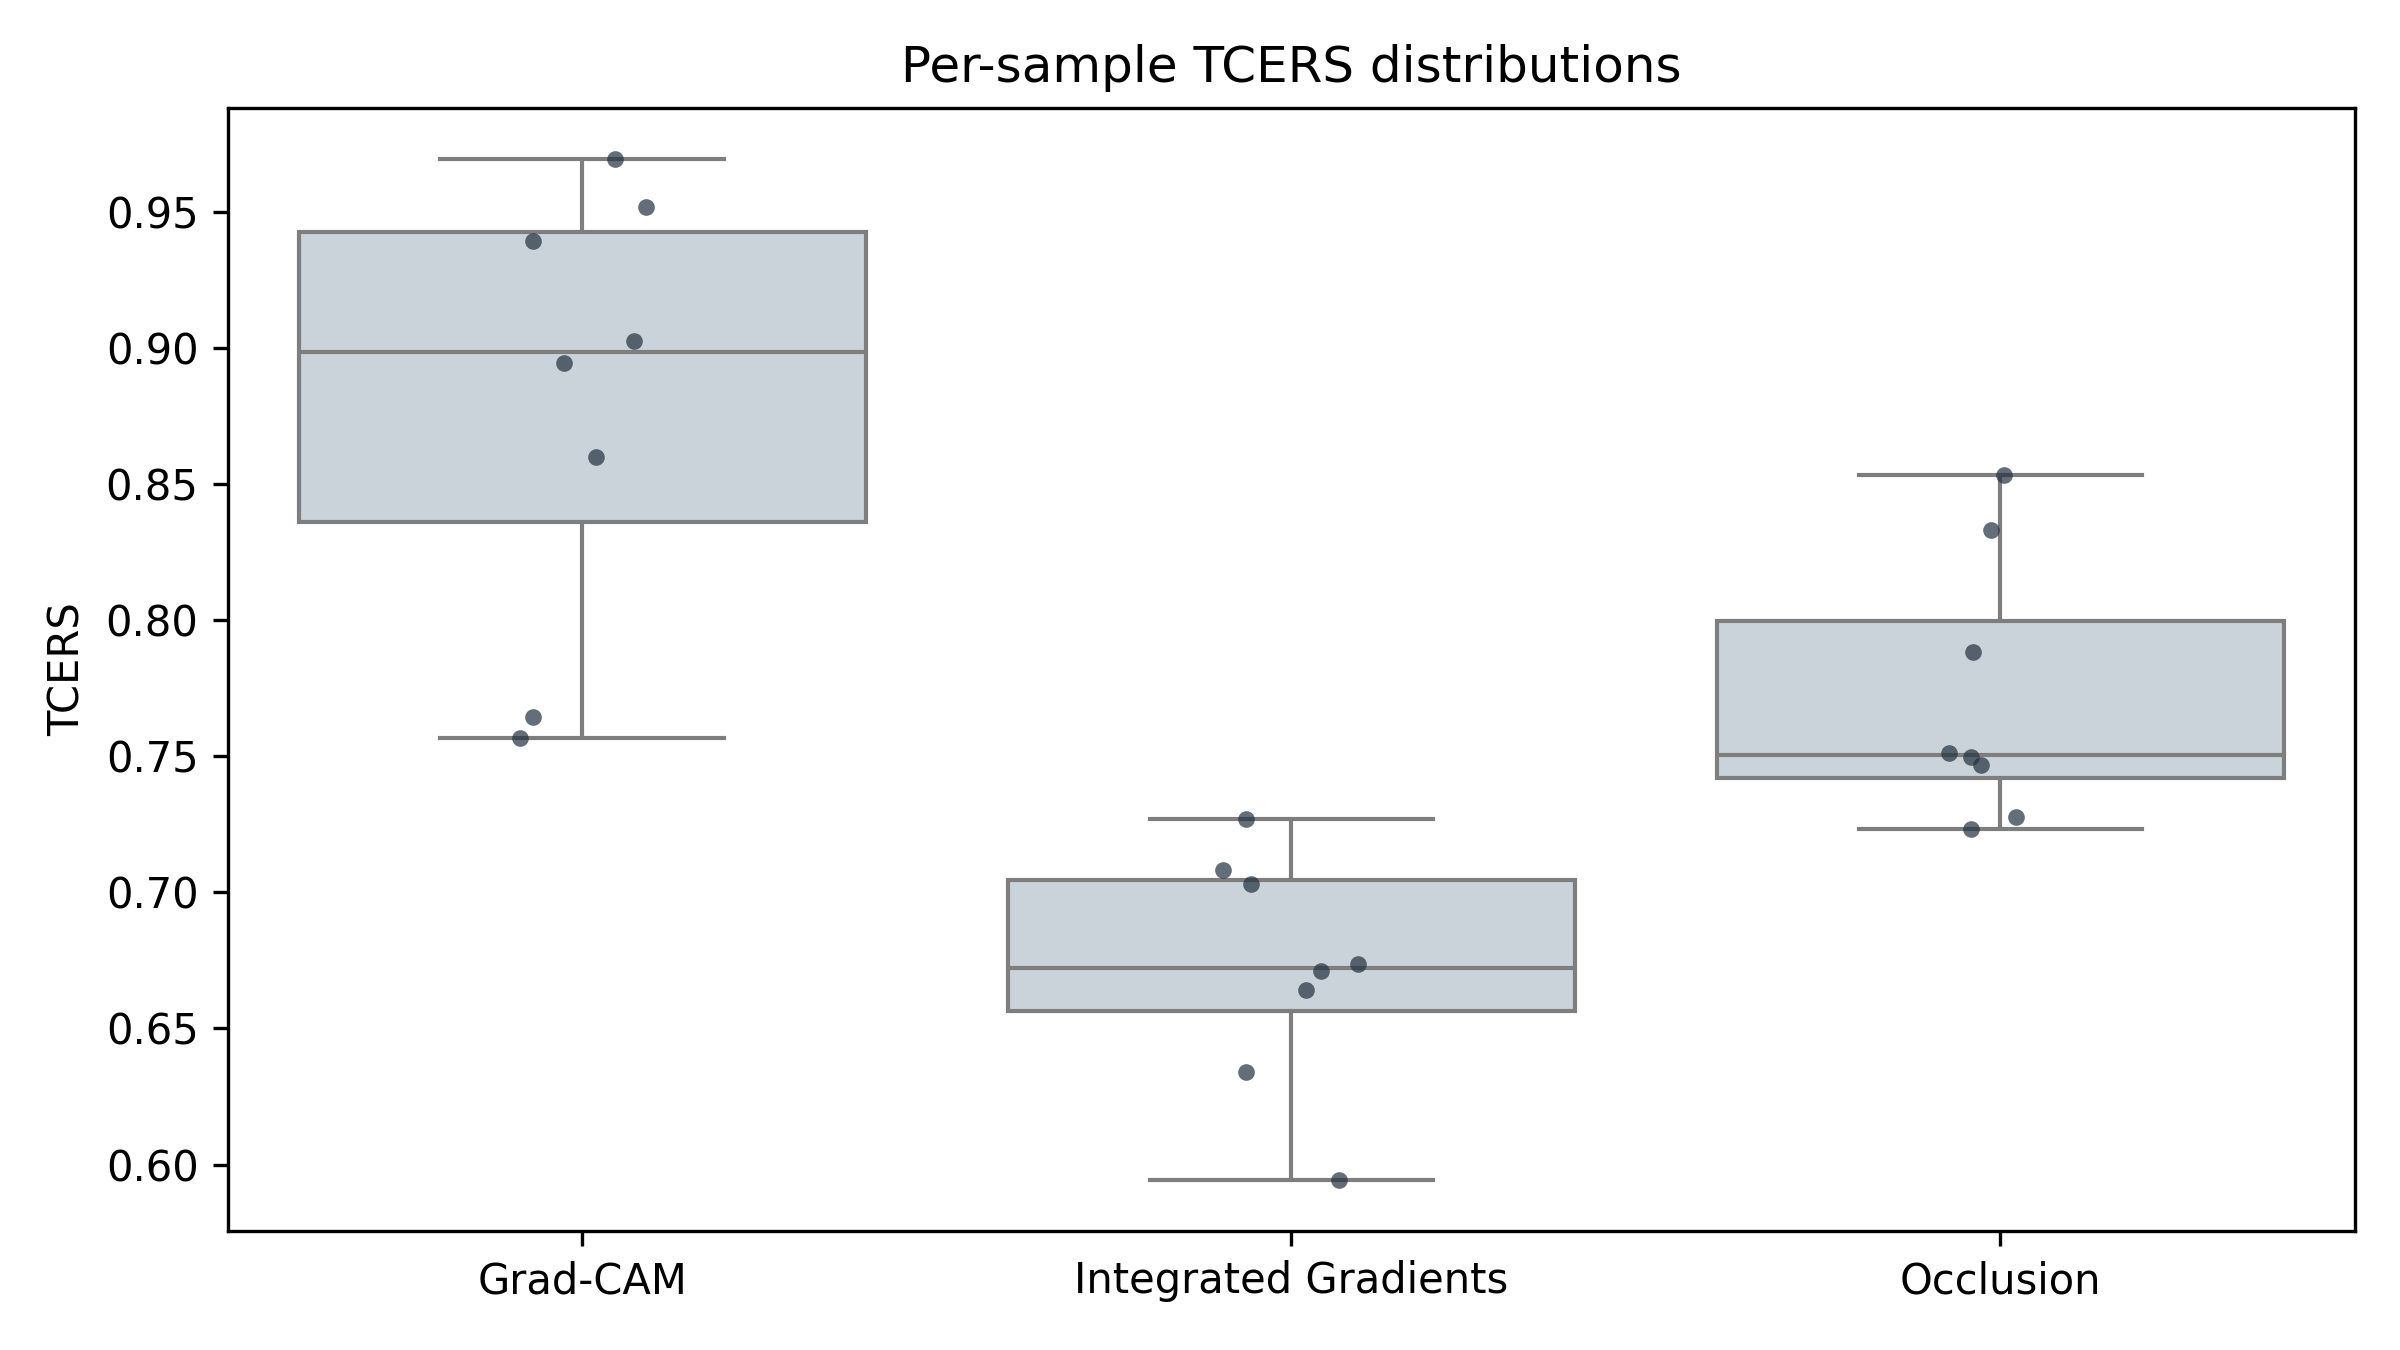

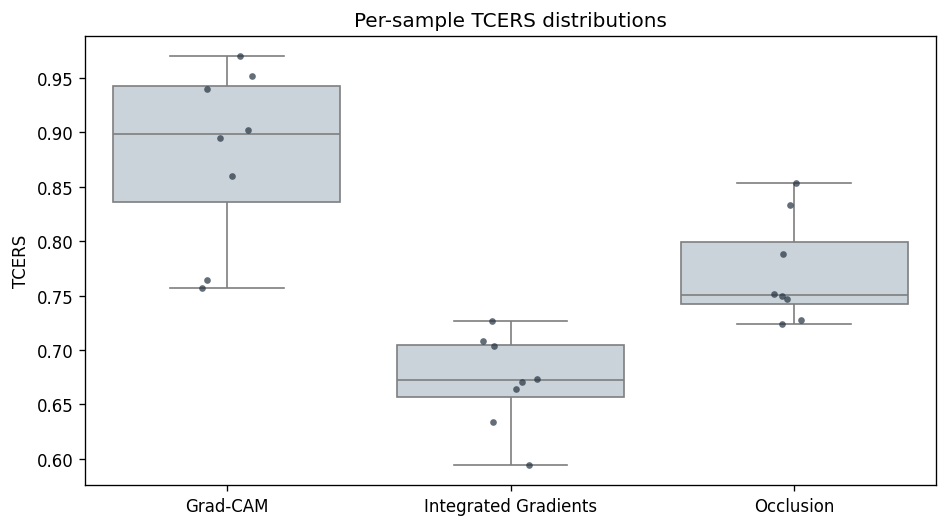

In [8]:
figure, axis = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=tcers_table, x="method", y="tcers", color="#C7D3DD", ax=axis)
sns.stripplot(data=tcers_table, x="method", y="tcers", color="#22313F", size=4, alpha=0.7, ax=axis)
axis.set(title="Per-sample TCERS distributions", xlabel="", ylabel="TCERS")
figure.tight_layout()
figure.savefig(Path("figures") / "statistical_distributions.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "statistical_distributions.png")))

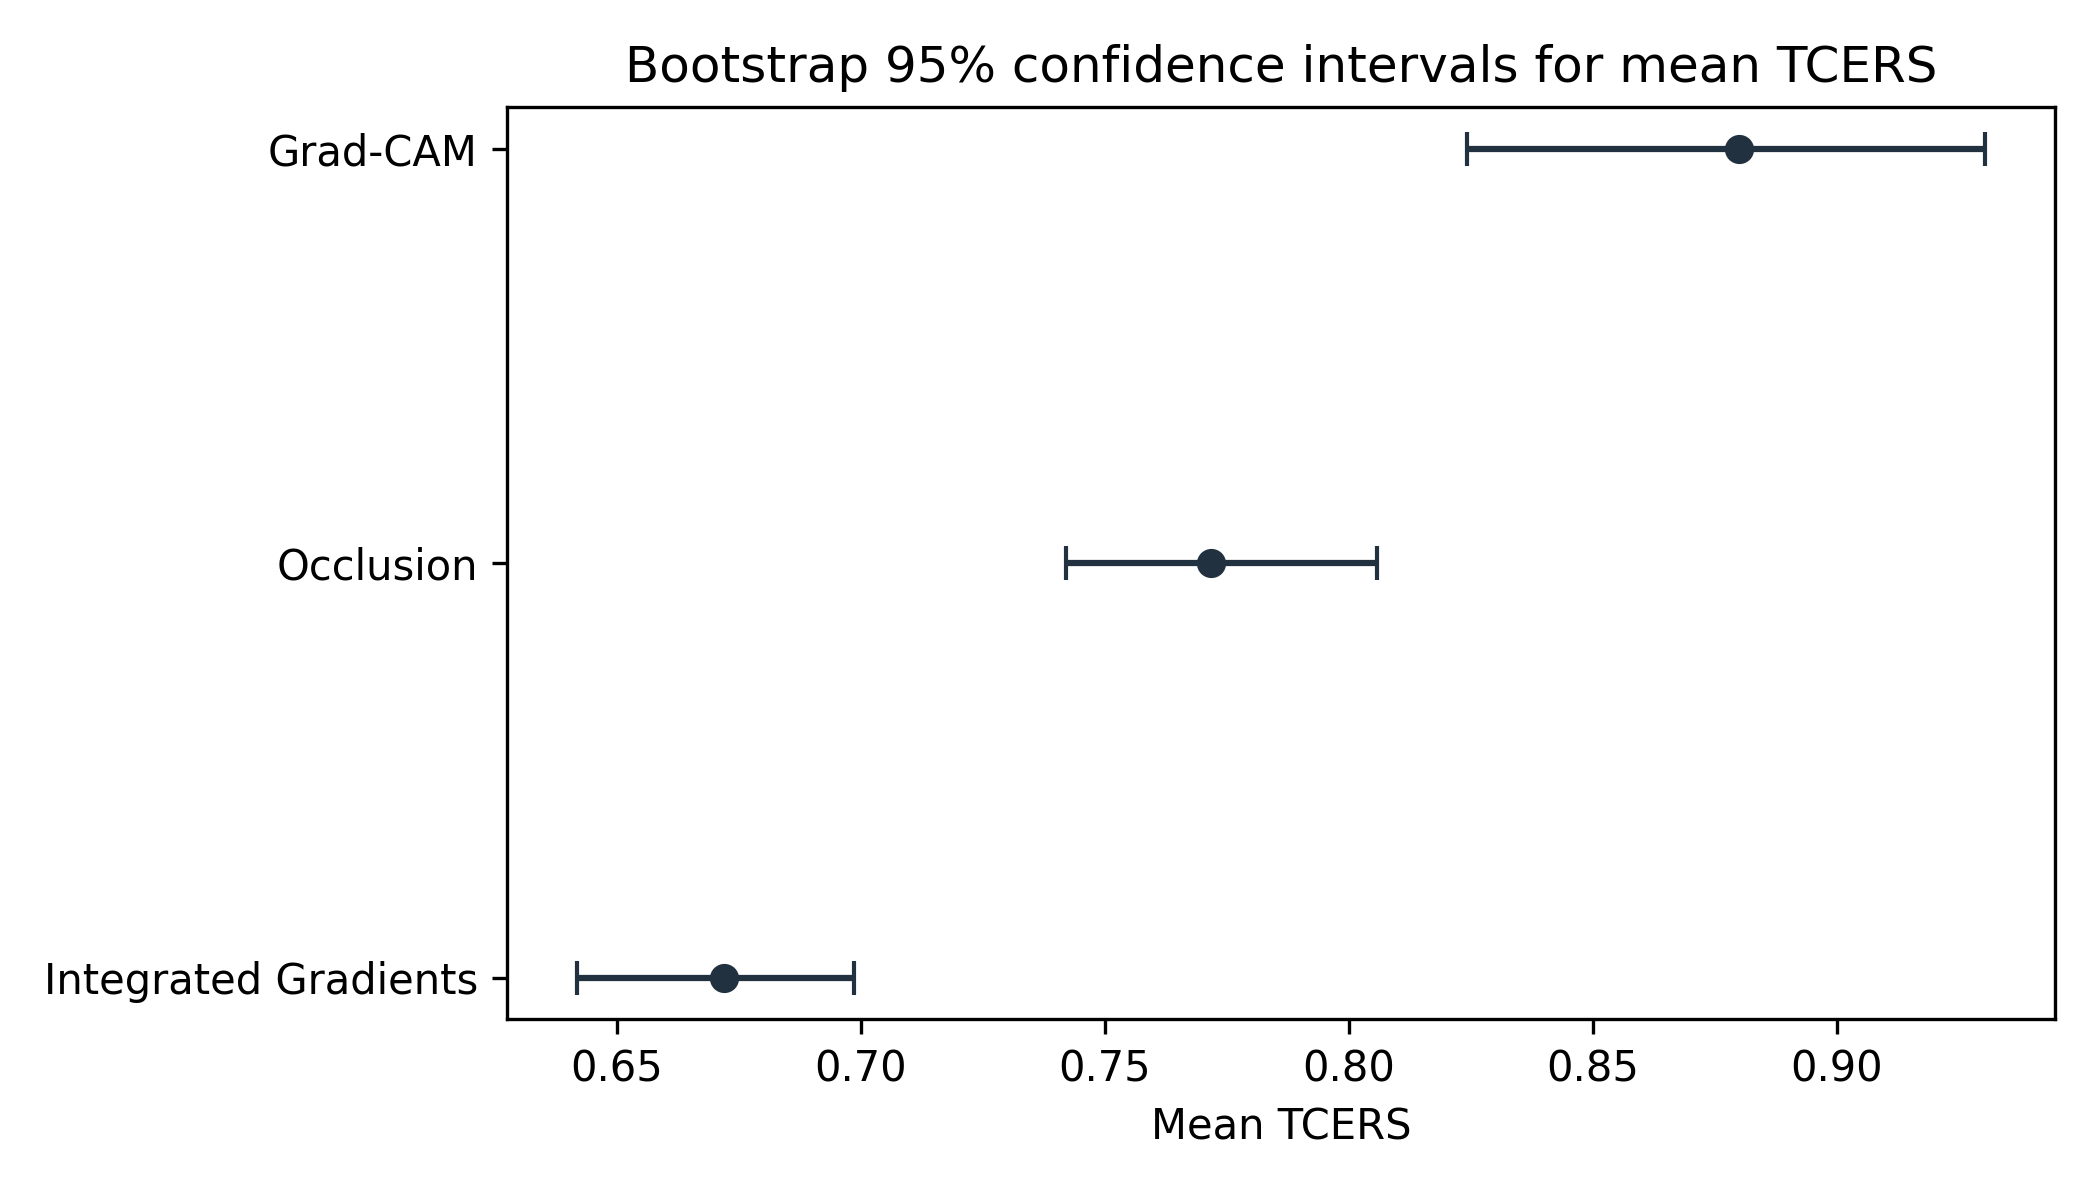

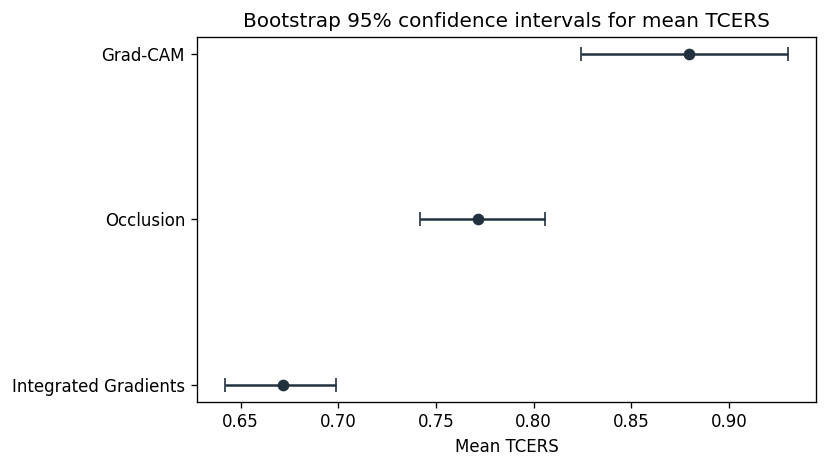

In [9]:
figure, axis = plt.subplots(figsize=(7, 4))
positions = np.arange(len(descriptive))
axis.errorbar(
    descriptive["mean"],
    positions,
    xerr=[
        descriptive["mean"] - descriptive["ci95_lower"],
        descriptive["ci95_upper"] - descriptive["mean"],
    ],
    fmt="o",
    capsize=4,
    color="#22313F",
)
axis.set_yticks(positions, descriptive["method"])
axis.set(title="Bootstrap 95% confidence intervals for mean TCERS", xlabel="Mean TCERS", ylabel="")
axis.invert_yaxis()
figure.tight_layout()
figure.savefig(Path("figures") / "statistical_confidence_intervals.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "statistical_confidence_intervals.png")))

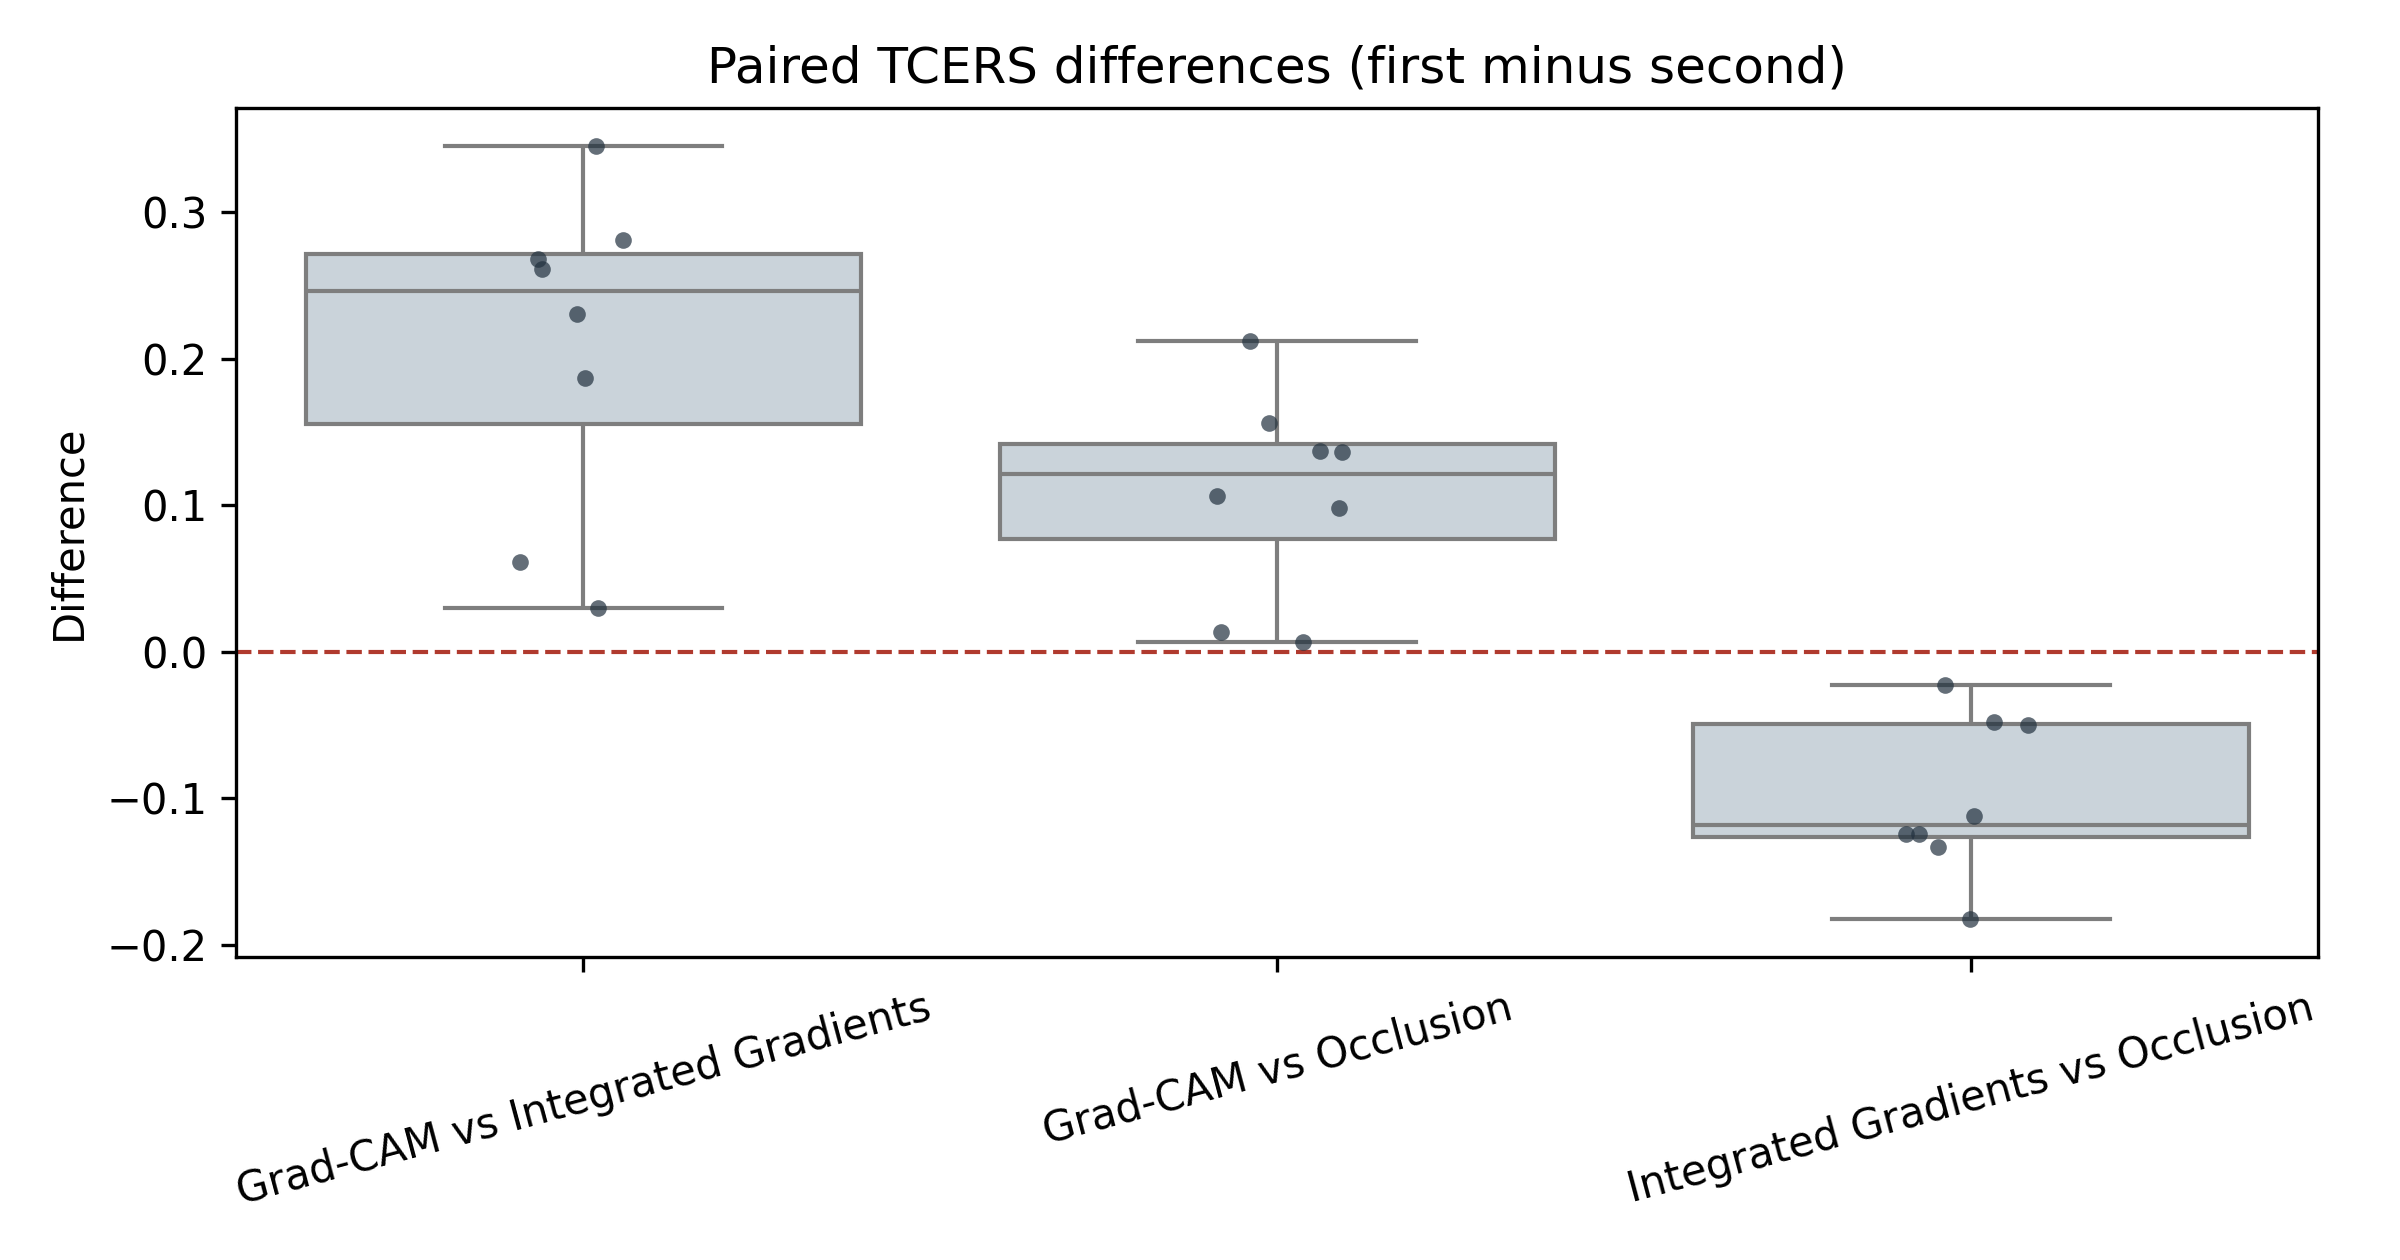

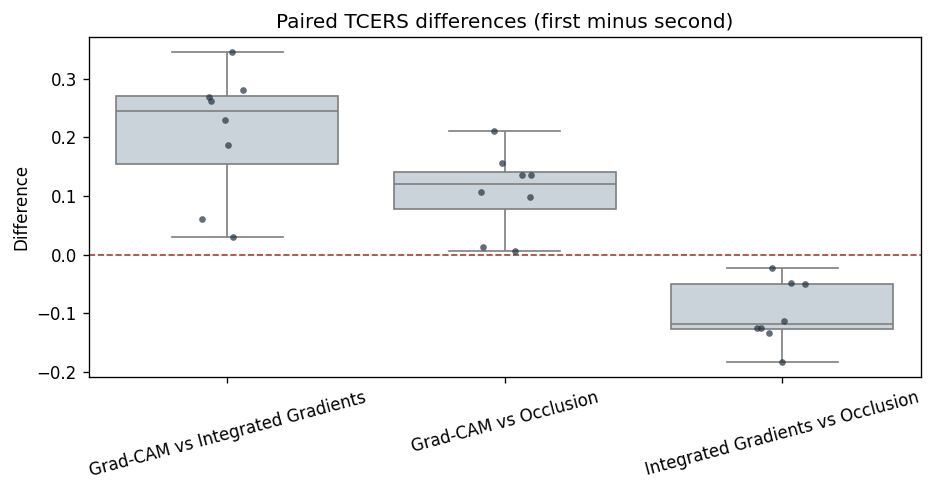

In [10]:
difference_rows = []
for first, second in combinations(methods, 2):
    aligned = tcers_table.pivot_table(
        index="sample", columns="method", values="tcers"
    ).dropna(subset=[first, second])
    for value in (aligned[first] - aligned[second]).values:
        difference_rows.append({"comparison": f"{first} vs {second}", "difference": value})

difference_table = pd.DataFrame(difference_rows)
figure, axis = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=difference_table, x="comparison", y="difference", color="#C7D3DD", ax=axis)
sns.stripplot(data=difference_table, x="comparison", y="difference", color="#22313F", size=4, alpha=0.7, ax=axis)
axis.axhline(0, color="#B03A2E", linestyle="--", linewidth=1)
axis.set(title="Paired TCERS differences (first minus second)", xlabel="", ylabel="Difference")
axis.tick_params(axis="x", rotation=15)
figure.tight_layout()
figure.savefig(Path("figures") / "statistical_paired_differences.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "statistical_paired_differences.png")))

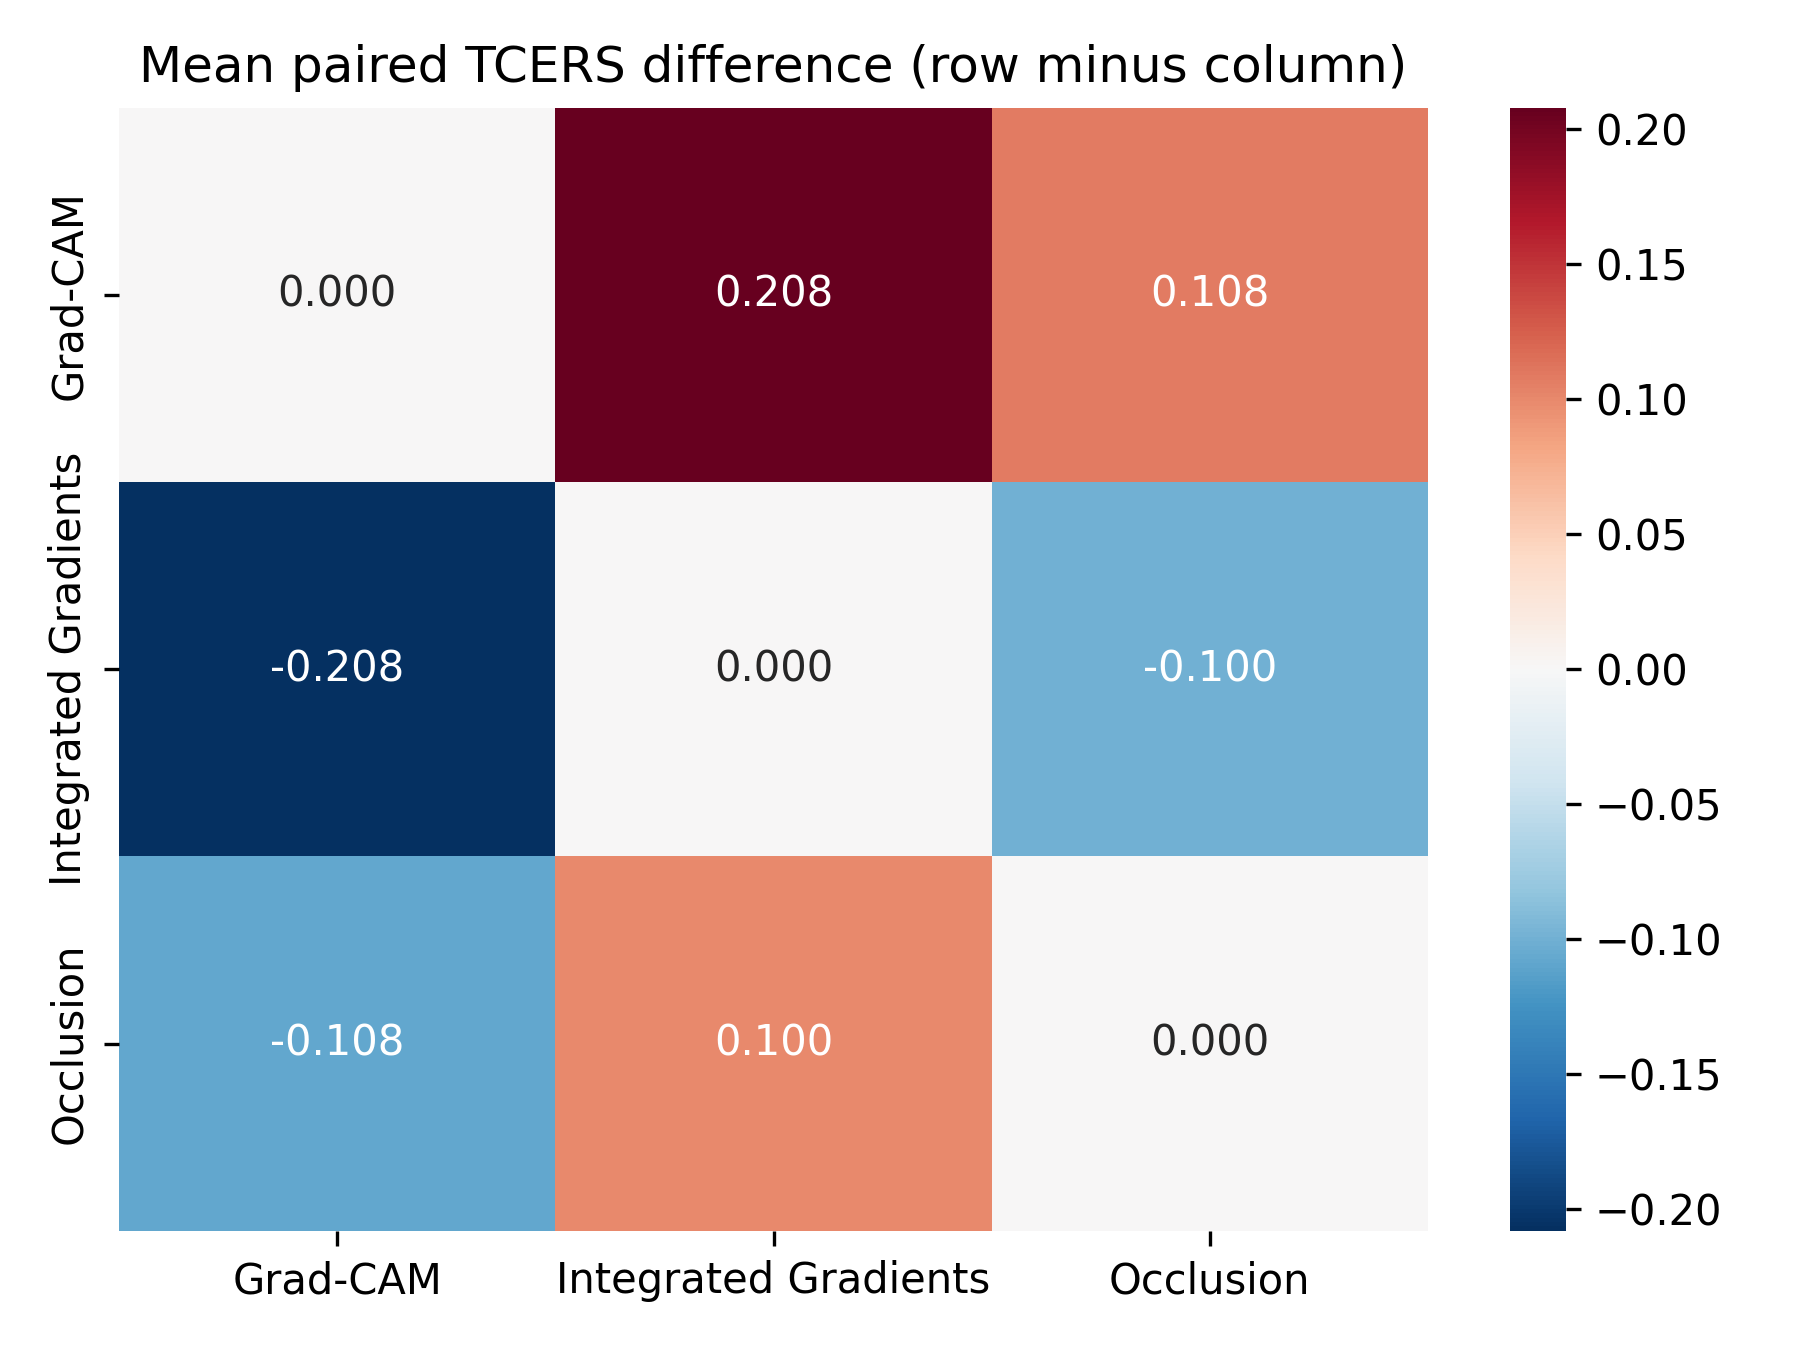

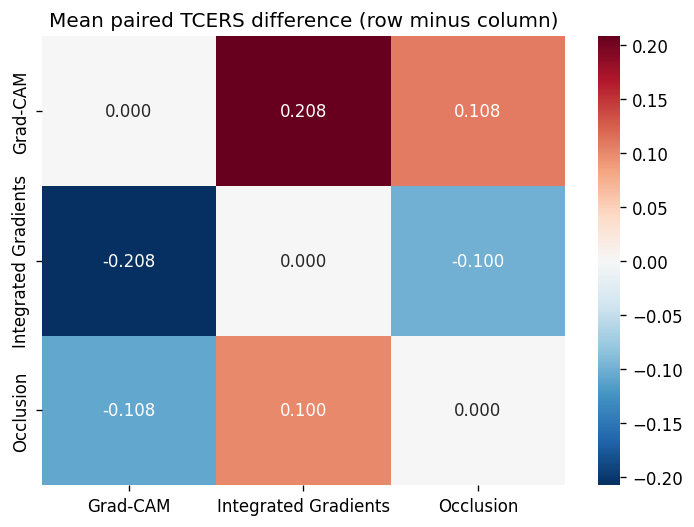

In [11]:
mean_difference = pd.DataFrame(index=methods, columns=methods, dtype=float)
for first in methods:
    for second in methods:
        aligned = tcers_table.pivot_table(
            index="sample", columns="method", values="tcers"
        ).dropna(subset=[first, second])
        mean_difference.loc[first, second] = (aligned[first] - aligned[second]).mean()

figure, axis = plt.subplots(figsize=(6, 4.5))
sns.heatmap(mean_difference.astype(float), annot=True, fmt=".3f", cmap="RdBu_r", center=0, ax=axis)
axis.set(title="Mean paired TCERS difference (row minus column)", xlabel="", ylabel="")
figure.tight_layout()
figure.savefig(Path("figures") / "statistical_difference_heatmap.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "statistical_difference_heatmap.png")))

## Reporting template

Use placeholders only after executing the notebook on real data:

> Across `N` test images and 14 perturbations, `METHOD_A` achieved a mean TCERS of `<mean>` (95% CI `[<lower>, <upper>]`), compared with `<mean>` for `METHOD_B` and `<mean>` for `METHOD_C`. The paired Wilcoxon test for `A vs B` returned `W = <statistic>`, Holm-adjusted `p = <p>`. The mean paired difference was `<difference>` with Cohen's $d_z = <dz>`. Prediction consistency was `<value>` for A, `<value>` for B, and `<value>` for C. These results are conditional on the selected perturbations, sample size, and architecture and should not be generalized without replication.

> **No values are fabricated in this notebook.** Every number above is produced by executing the pipeline.

## Limitations

- **Small sample size.** The first eight test images are not a representative sample of the full test distribution. Increase `NUM_SAMPLES` in Notebook 04 for a final analysis and rerun Notebooks 05–06.
- **Dependence structure.** Images from the same breed or photographer may be correlated; the paired tests treat samples as exchangeable.
- **Composite metric.** TCERS is proposed, not validated. Report its components and the weight-sensitivity results.
- **Perturbation scope.** Conclusions apply only to the four perturbation families and parameter grids used here.
- **Model specificity.** Explanations and stability are properties of this checkpoint, not of ResNet18 or Grad-CAM in general.

## References

- Wilcoxon, F. (1945). Individual Comparisons by Ranking Methods. *Biometrics Bulletin*.
- Holm, S. (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*.
- Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences*.
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*.